# Planet comparison: the close-in rocky population

Every rocky planet ($R_p < 2\,R_\oplus$) of the archive with $a/R_\star < 3.5$, fitted at its own geometry and its own PandExo noise on the JWST bands PandExo covers (NIRSpec G395H NRS1, NRS2, both arrays jointly, MIRI/LRS): the bias $\Delta A_B$ of the point-source fit of a noiseless hyperillumination truth, the Fisher $\sigma_{A_B}$ at the planet's noise, and their ratio, for the $A_B$-only fit and the joint $(A_B, F)$ fit. The same per-planet decision as `Bias_Maps.ipynb` 1.2, for the whole population at once. Planet parameters come from `HItargets_utils.CUSTOM` where an entry exists (the archive frame carries them via `apply_custom`), otherwise from the archive.

1. **Sample** - one table.
2. **Noise** - $\sigma_{1\,\rm min}$ per planet and band.
3. **Fits** - the long table `fits` and a pivot helper `lookup`.
4. **Heatmaps** - bias and $|\Delta A_B|/\sigma_{A_B}$, planets $\times$ bands.
5. **The paper planets in the population**.

Runtime: PandExo takes seconds per planet and mode, the fits a few minutes in parallel; restart the kernel before a rerun (SPIDERMAN worker memory). Nothing is cached or written to disk (paper figures excepted, with `PAPER_MODE = True`).

In [1]:
import contextlib, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
from matplotlib.patches import Rectangle
from IPython.display import display
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers between parallel blocks
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
from simple_bias_analysis import *
from simple_bias_analysis import _instrument_row   # one (planet, band, fit) row of instrument_retrievals; lets section 3 run all planets x bands x fits in one parallel block
from HItargets_utils import *
from paper_plot_utils import paper_figure, paper_theme

AGG = "NASAExoArchive_2026-08-21_aggregate_short.csv"   # the notebook sits next to the archive tables
set_plot_style()

# Sample cut (wider than the paper's ROCKY_MAX_RADE, to see what that cut leaves out)
MAX_RADE_SAMPLE, MAX_A_RS = 2.0, 3.5   # [R_Earth], a/R*

# Baseline settings (HItargets_utils.py)
A_B_true = DEFAULT_A_B
A_model = ConstantBandAlbedo(DEFAULT_A)
u, u_B = DEFAULT_U, DEFAULT_U_B
n_orbits, n_bins = DEFAULT_N_ORBITS, DEFAULT_N_BINS
kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)
bounds, F_bounds = A_B_FIT_BOUNDS, F_BOUNDS   # fit ranges: A_B may go below the physical floor 0
sigma_prior = flat_prior_sigma(A_B_BOUNDS)   # Fisher sigma_A_B at or above the std of the physical range -> "unconstrained"

# Bands: the paper's retrievals that PandExo covers (MIRI imaging has no PandExo mode). A "+"-joined key is one joint fit of those detectors.
BANDS = [instrument_key(b) for b in JWST_RETRIEVALS if all(PANDEXO_MODES[d] for d in detectors(b))]
DETECTORS = list(dict.fromkeys(d for b in BANDS for d in detectors(b)))
BAND_LABEL = {b: instrument_label(b, oneline=True) for b in BANDS}
FITS = {"naive": "$A_B$-only fit", "naive_redist": "joint ($A_B$, $F$) fit"}

norm_name = lambda s: s.lower().replace(" ", "").replace("-", "").replace("_", "")   # loose planet names, as the utilities match them
is_paper = lambda name: norm_name(name) in {norm_name(p) for p in PAPER_PLANETS}

def show(df, digits=3, gradient=None, **kw):
    '''A DataFrame with floats to `digits` significant figures and NaN as a dash; gradient=(cmap, vmin, vmax) colours the float cells.'''
    floats = [c for c in df.columns if pd.api.types.is_float_dtype(df[c])]
    st = df.style.format({c: f"{{:.{digits}g}}" for c in floats}, na_rep="-")
    if gradient: st = st.background_gradient(cmap=gradient[0], vmin=gradient[1], vmax=gradient[2], subset=floats, **kw)
    display(st)

## 1. Sample
The archive frame with `CUSTOM` applied (`archive_frame`), cut to the rocky close-in population, and one `PlanetParams` per planet (`hi_planets_by_name`). `paper` marks the members of `PAPER_PLANETS`, `custom` the planets with a curated entry. Planets that do not occult at their geometry ($b \geq 1 + R_p/R_\star$) are listed and left out of the fits.

In [2]:
arch = archive_frame(AGG).set_index("pl_name")
cut = (arch.pl_ratror < MAX_R1_OVER_R2) & (arch.a_over_r2 > 1. + arch.pl_ratror) & (arch.pl_rade < MAX_RADE_SAMPLE) & (arch.a_over_r2 < MAX_A_RS)
planets = hi_planets_by_name(list(arch.index[cut]))   # {name: PlanetParams}

sample = pd.DataFrame([dict(name=nm, paper=is_paper(nm), custom=norm_name(nm) in {norm_name(c) for c in CUSTOM}, a_rs=pl.R / pl.r2, rp_rs=pl.r1 / pl.r2, rp_rearth=arch.loc[nm, "pl_rade"],
                            incl=pl.incl, b=pl.R / pl.r2 * np.cos(np.radians(pl.incl)), T_eff=pl.T2_eff, kmag=arch.loc[nm, "sy_kmag"], esm=arch.loc[nm, "ESM"], period_h=24. * pl.period, t_obs_h=n_orbits * 24. * pl.period)
                       for nm, pl in planets.items()]).sort_values("a_rs").reset_index(drop=True)
sample["occults"] = sample.b < 1. + sample.rp_rs
ORDER = list(sample.name)                                # by a/R*: the row order of every table and heatmap
fit_planets = {nm: planets[nm] for nm in sample.loc[sample.occults, "name"]}

print(f"{len(sample)} planets with R_p < {MAX_RADE_SAMPLE:g} R_Earth and a/R* < {MAX_A_RS:g}: {sample.paper.sum()} of the {len(PAPER_PLANETS)} PAPER_PLANETS, {sample.custom.sum()} with a CUSTOM entry, "
      f"{(sample.rp_rearth >= ROCKY_MAX_RADE).sum()} at or above ROCKY_MAX_RADE = {ROCKY_MAX_RADE:g} R_Earth")
if (~sample.occults).any(): print("no occultation at their geometry, left out of the fits:", ", ".join(sample.loc[~sample.occults, "name"]))
missing = [p for p in PAPER_PLANETS if not is_paper(p) or norm_name(p) not in {norm_name(n) for n in sample.name}]
if missing: print("PAPER_PLANETS outside the sample cut:", ", ".join(missing))
show(sample.set_index("name").drop(columns=["occults"]))

44 planets with R_p < 2 R_Earth and a/R* < 3.5: 9 of the 9 PAPER_PLANETS, 25 with a CUSTOM entry, 3 at or above ROCKY_MAX_RADE = 1.7 R_Earth
no occultation at their geometry, left out of the fits: Kepler-1547 b, Kepler-1107 b


,paper,custom,a_rs,rp_rs,rp_rearth,incl,b,T_eff,kmag,esm,period_h,t_obs_h
name,,,,,,,,,,,,
KOI-1843.03,False,True,1.9,0.0123,0.602,72,0.587,3.58e+03,11.1,1.47,4.25,21.2
TOI-2431 b,True,True,2.08,0.0213,1.51,74,0.573,4.11e+03,7.55,26,5.38,26.9
TOI-2260 b,True,True,2.22,0.0158,1.62,69.7,0.77,5.53e+03,8.68,8.63,8.46,42.3
K2-141 b,True,True,2.29,0.0204,1.51,86.3,0.148,4.6e+03,8.4,16.1,6.73,33.6
Kepler-1340 b,False,False,2.31,0.00962,1.55,80.5,0.381,6.33e+03,13.2,0.328,16,79.8
K2-157 b,False,True,2.4,0.00996,0.934,89.2,0.0336,5.33e+03,11,1.12,8.77,43.8
K2-183 b,False,True,2.5,0.0117,1.24,90,1.53e-16,5.52e+03,11,1.48,11.3,56.3
EPIC 206042996 c,False,True,2.6,0.0223,1.64,89.9,0.00454,4.06e+03,13.1,1.89,8.52,42.6
K2-131 b,True,True,2.66,0.0204,1.69,85,0.232,5.12e+03,10.1,4.32,8.86,44.3


## 2. Noise
One PandExo run per planet and mode, binned per detector exactly as `rms_1min` does it (`run_pandexo` + `rms_1min_pandexo`, the planet's own $T_{14}$), in parallel across planets. A planet whose run fails (archive value missing, saturation) keeps NaN and is reported; it is still fitted (the bias is noise-independent) but gets no Fisher $\sigma$.

What to look for: the noise follows $10^{0.2K}$ (dotted) until the background (faint end) or saturation (bright end) take over; most of the sample sits where no phase-curve measurement is possible.

In [3]:
RUNS = {}   # PandExo mode -> detectors binned from the same run
for d in DETECTORS: RUNS.setdefault(PANDEXO_MODES[d], []).append(d)

def pandexo_sigmas(pl):
    import warnings; warnings.filterwarnings("ignore")
    sig, err = {}, {}
    for mode, dets in RUNS.items():
        try:
            with contextlib.redirect_stdout(io.StringIO()): result = run_pandexo(pl.name, dets[0], verbose=False, t14_h=pl.T14)
        except Exception as e:
            err.update({d: f"{type(e).__name__}: {e}" for d in dets}); continue
        for d in dets:
            try: sig[d] = float(rms_1min_pandexo(result, pl.T14, filter_lambda(d)))
            except Exception as e: err[d] = f"{type(e).__name__}: {e}"
    return pl.name, sig, err

out = Parallel(n_jobs=-1, backend="loky")(delayed(pandexo_sigmas)(pl) for pl in fit_planets.values())
get_reusable_executor().shutdown(wait=True)
sigma_1min = {nm: sig for nm, sig, _ in out}   # {planet: {detector: ppm/min}}: PandExo is not cached, keep this dict
for nm, _, err in out:
    for d, e in err.items(): print(f"{nm} [{instrument_label(d, oneline=True)}]: no noise level ({e})")

noise = pd.DataFrame({nm: {instrument_label(d, oneline=True): s.get(d, np.nan) for d in DETECTORS} for nm, s in sigma_1min.items()}).T.reindex([n for n in ORDER if n in sigma_1min])
show(noise.join(sample.set_index("name")[["kmag", "paper"]]), gradient=("viridis_r", 30., 1000.))

,NIRSpec G395H NRS1,NIRSpec G395H NRS2,MIRI LRS,kmag,paper
KOI-1843.03,158,187,473,11.1,False
TOI-2431 b,39.1,49.4,62.9,7.55,True
TOI-2260 b,58.4,74.3,114,8.68,True
K2-141 b,52.8,68,99.2,8.4,True
Kepler-1340 b,447,569,4.11e+03,13.2,False
K2-157 b,159,204,572,11,False
K2-183 b,163,209,587,11,False
EPIC 206042996 c,375,472,3.04e+03,13.1,False
K2-131 b,105,135,280,10.1,True
TOI-561 b,52.8,67.5,99.4,8.39,True


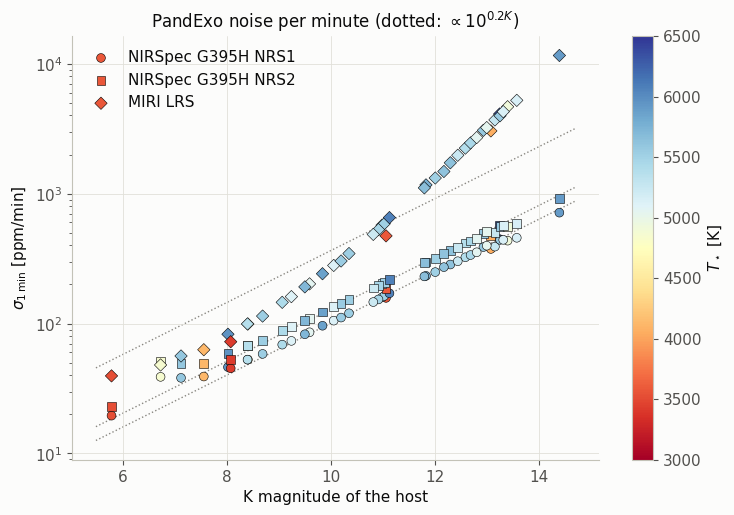

In [4]:
PAPER_MODE = False
props = sample.set_index("name").loc[noise.index]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for d, mk in zip(DETECTORS, "osD^"):
    s = noise[instrument_label(d, oneline=True)].to_numpy(float); ok = np.isfinite(s)
    sc = ax.scatter(props.kmag[ok], s[ok], c=props.T_eff[ok], cmap="RdYlBu", vmin=3000, vmax=6500, marker=mk, s=40, edgecolor="k", linewidths=.4, zorder=3, label=instrument_label(d, oneline=True))
    if ok.any():   # photon-noise guide through the median of the detector
        kk = np.linspace(props.kmag.min() - .3, props.kmag.max() + .3, 50)
        ax.plot(kk, np.median(s[ok] / 10 ** (0.2 * props.kmag[ok])) * 10 ** (0.2 * kk), ":", color=MUTED, lw=1, zorder=1)
ax.set_yscale("log"); ax.set_xlabel("K magnitude of the host"); ax.set_ylabel(r"$\sigma_{1\,\rm min}$ [ppm/min]")
ax.set_title("PandExo noise per minute (dotted: $\\propto 10^{0.2K}$)")
fig.colorbar(sc, ax=ax, label=r"$T_\star$ [K]"); ax.legend(loc="upper left")
paper_figure("planetcomp_sigma1min", PAPER_MODE, fig=fig)
plt.show()

## 3. Fits
One row per planet, band and fit (`_instrument_row`, the row function of `instrument_retrievals`): the noiseless hyperillumination truth at `A_B_true`, fitted with the point-source model with a free baseline at the planet's geometry, and the Fisher $\sigma$ at its noise. Derived: `bias_sigma` $= |\Delta A_B|/\sigma_{A_B}$, `sigma_1min_crit` (single detectors), `verdict`, `t_crit_h`, `below_zero` (fitted $A_B < 0$, outside the physical range), `railed` (on a bound of the fit range, a safety check), and for the joint fit `F_sigma` $= F/\sigma_F$. Hosts outside the stellar model are left out per band with a note.

`fits` is the long table. `lookup(value, fit)` pivots one column to planets (by $a/R_\star$) $\times$ bands; `both(value)` puts the two fits side by side. Shown here: $|\Delta A_B|/\sigma_{A_B}$ and the verdicts; everything else is one call away.

In [5]:
l1, l2 = filter_lambda(DETECTORS[0])
cfg = FittingConfig(planet=next(iter(fit_planets.values())), filter_path=filter_loc(DETECTORS[0]), l1=l1, l2=l2, A_=A_model,
                    sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_B=u_B, u=u)   # band and planet are replaced per row; sigma_1min = 100 only serves rows without a noise level
supported = {d: {pl.name for pl in drop_unsupported_hosts(instrument_cfg(cfg, d), list(fit_planets.values()))} for d in DETECTORS}

tasks, skipped = [], []
for band in BANDS:
    dets = detectors(band)
    for nm, pl in fit_planets.items():
        if not all(nm in supported[d] for d in dets): continue
        s = sigma_1min.get(nm, {})
        if len(dets) > 1 and not all(d in s for d in dets): skipped.append(f"{nm} ({BAND_LABEL[band]})"); continue   # a joint fit weights its detectors by their noise
        for fit in FITS: tasks.append((nm, fit, (cfg, A_B_true, pl, band, s, fit == "naive_redist", bounds, F_bounds, kw)))
if skipped: print("joint fits left out (a detector without a noise level):", ", ".join(skipped))
print(f"{len(tasks)} fits")

rows = pmap(lambda nm, fit, args: dict(name=nm, fit=fit, **_instrument_row(*args)), tasks)
fits = pd.DataFrame(rows).rename(columns={"instrument": "band"}).merge(sample[["name", "paper", "a_rs", "T_eff", "kmag", "rp_rearth", "t_obs_h"]], on="name")
fits["has_noise"] = [all(d in sigma_1min.get(n, {}) for d in detectors(b)) for n, b in zip(fits.name, fits.band)]
fits["bias_sigma"], fits["sigma_1min_crit"] = measurability(fits.bias_A_B, fits.sigma_A_B, fits.sigma_1min)
fits["verdict"] = bias_verdict(fits.bias_sigma, fits.sigma_A_B, sigma_prior)
fits.loc[~fits.has_noise, "verdict"] = VERDICT_NO_NOISE
fits["t_crit_h"] = critical_time(fits.t_obs_h, fits.bias_sigma, fits.verdict)
fits["below_zero"] = fits.A_B_fit < 0.   # below the physical floor, allowed by the fit range
fits["railed"] = is_railed(fits.A_B_fit, bounds)
fits["F_sigma"] = fits.F_fit / fits.sigma_F

if fits.below_zero.any(): print("fitted A_B < 0:", ", ".join(f"{r.name} [{BAND_LABEL[r.band]}, {r.fit}]" for r in fits[fits.below_zero].itertuples()))
if fits.railed.any(): print("railed fits:", ", ".join(f"{r.name} [{BAND_LABEL[r.band]}, {r.fit}]" for r in fits[fits.railed].itertuples()))
for fit, label in FITS.items():
    f = fits[fits.fit == fit]
    print(f"{label.replace('$', '')}: " + ", ".join(f"{(f.verdict == v).sum()} {v}" for v in (VERDICT_NEEDS_HI, VERDICT_NAIVE_OK, VERDICT_UNCONSTRAINED, VERDICT_NO_NOISE)) + f" (of {len(f)} planet-bands)")


def lookup(value, fit="naive", label=True):
    '''Planets (rows, by a/R*) x bands (columns) of one column of `fits` for one fit.'''
    p = fits[fits.fit == fit].pivot(index="name", columns="band", values=value).reindex(index=[n for n in ORDER if n in set(fits.name)], columns=BANDS)
    return p.rename(columns=BAND_LABEL) if label else p

def both(value):
    '''The two fits side by side, with a/R* and the paper flag in front.'''
    t = pd.concat({FITS[f].replace("$", ""): lookup(value, f) for f in FITS}, axis=1)
    t.insert(0, ("", "paper"), sample.set_index("name").paper.reindex(t.index)); t.insert(0, ("", "a/R*"), sample.set_index("name").a_rs.reindex(t.index))
    return t

336 fits


A_B-only fit: 5 needs hyperillum, 67 naive OK, 96 unconstrained, 0 no noise level (of 168 planet-bands)
joint (A_B, F) fit: 9 needs hyperillum, 56 naive OK, 103 unconstrained, 0 no noise level (of 168 planet-bands)


In [6]:
show(both("bias_sigma"), gradient=("viridis", 0., 1.5))   # |Delta A_B| / sigma_A_B at the planet's own noise; >= 1: the point-source fit is measurably wrong
display(pd.concat({FITS[f].replace("$", ""): lookup("verdict", f) for f in FITS}, axis=1).fillna("-"))
# Other columns: lookup("bias_A_B" | "sigma_A_B" | "sigma_1min_crit" | "t_crit_h" | "A_B_fit", fit), lookup("F_fit" | "F_sigma", "naive_redist"), or both(...)

A_B-only fit                     \
band             NIRSpec G395H NRS1 NIRSpec G395H NRS2   
name                                                     
KOI-1843.03           unconstrained      unconstrained   
TOI-2431 b         needs hyperillum   needs hyperillum   
TOI-2260 b                 naive OK           naive OK   
K2-141 b                   naive OK           naive OK   
Kepler-1340 b         unconstrained      unconstrained   
K2-157 b              unconstrained      unconstrained   
K2-183 b              unconstrained      unconstrained   
EPIC 206042996 c           naive OK      unconstrained   
K2-131 b                   naive OK           naive OK   
TOI-561 b                  naive OK           naive OK   
Kepler-990 c          unconstrained      unconstrained   
Kepler-78 b                naive OK           naive OK   
TOI-1444 b                 naive OK           naive OK   
K2-223 b              unconstrained      unconstrained   
EPIC 220674823 b           naive OK           naive OK   
TOI-1798.02                naive OK           naive OK   
HD 80653 b                 naive OK           naive OK   
EPIC 212624936 b      unconstrained      unconstrained   
EPIC 220554210 c           naive OK      unconstrained   
Kepler-1368 b         unconstrained      unconstrained   
EPIC 201427007 b      unconstrained      unconstrained   
Kepler-879 c          unconstrained      unconstrained   
TOI-6255 b                 naive OK           naive OK   
Kepler-780 b          unconstrained      unconstrained   
Kepler-1566 b         unconstrained      unconstrained   
Kepler-407 b          unconstrained      unconstrained   
EPIC 220492298 b      unconstrained      unconstrained   
WASP-47 e                  naive OK           naive OK   
Kepler-1932 b         unconstrained      unconstrained   
K2-396 b                   naive OK           naive OK   
Kepler-1489 c         unconstrained      unconstrained   
GJ 367 b                   naive OK           naive OK   
TOI-431 b                  naive OK           naive OK   
Kepler-653 c          unconstrained      unconstrained   
Kepler-1323 b         unconstrained      unconstrained   
Kepler-10 b                naive OK           naive OK   
HD 20329 b                 naive OK           naive OK   
Kepler-828 b          unconstrained      unconstrained   
Kepler-1228 b         unconstrained      unconstrained   
Kepler-1814 c         unconstrained      unconstrained   
Kepler-1873 b         unconstrained      unconstrained   
Kepler-1317 b         unconstrained      unconstrained   

                                                              \
band             NIRSpec G395H NRS1 + NRS2          MIRI LRS   
name                                                           
KOI-1843.03                  unconstrained     unconstrained   
TOI-2431 b                needs hyperillum  needs hyperillum   
TOI-2260 b                        naive OK          naive OK   
K2-141 b                  needs hyperillum          naive OK   
Kepler-1340 b                unconstrained     unconstrained   
K2-157 b                     unconstrained     unconstrained   
K2-183 b                          naive OK     unconstrained   
EPIC 206042996 c                  naive OK     unconstrained   
K2-131 b                          naive OK          naive OK   
TOI-561 b                         naive OK          naive OK   
Kepler-990 c                 unconstrained     unconstrained   
Kepler-78 b                       naive OK     unconstrained   
TOI-1444 b                        naive OK          naive OK   
K2-223 b                     unconstrained     unconstrained   
EPIC 220674823 b                  naive OK     unconstrained   
TOI-1798.02                       naive OK          naive OK   
HD 80653 b                        naive OK          naive OK   
EPIC 212624936 b             unconstrained     unconstrained   
EPIC 220554210 c                  naive OK     unconstrained   
Kepl

What to look for: the bias is nearly band-independent and falls with $a/R_\star$, so the best band of a planet is set by its noise and thermal contrast; the joint fit's bias is larger (part of the nightside signal goes into $F$) but so is its $\sigma$. The verdict table says, per planet and band, whether a 5-orbit observation can tell the two irradiation models apart.

## 4. Heatmaps
Rows are the planets by $a/R_\star$ (in brackets; bold = `PAPER_PLANETS`), columns the bands. Left: $\Delta A_B$ (noise-independent, colour centred on zero). Right: $|\Delta A_B|/\sigma_{A_B}$ on a log scale, hatched where $A_B$ is unconstrained, a dash where there is no noise level. One figure per fit.

In [7]:
def heatmap(ax, p, norm, cmap, fmt, hatch=None):
    v = p.to_numpy(float)
    im = ax.imshow(np.ma.masked_invalid(v), aspect="auto", cmap=cmap, norm=norm, interpolation="nearest")
    ax.set_xticks(range(p.shape[1]), [instrument_label(b) for b in p.columns], fontsize=8)
    ax.set_yticks(range(p.shape[0]), [f"{n}  ({sample.set_index('name').a_rs[n]:.2f})" for n in p.index], fontsize=8)
    for lab, n in zip(ax.get_yticklabels(), p.index):
        if is_paper(n): lab.set_fontweight("bold")
    ax.tick_params(axis="x", top=True, labeltop=True, bottom=False, labelbottom=False); ax.grid(False)
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            if np.isfinite(v[i, j]):
                r, g, b, _ = im.cmap(norm(v[i, j]))
                ax.text(j, i, fmt.format(v[i, j]), ha="center", va="center", fontsize=7, color="k" if 0.299 * r + 0.587 * g + 0.114 * b > 0.55 else "w")
            else:
                ax.text(j, i, "-", ha="center", va="center", fontsize=7, color=MUTED)
            if hatch is not None and bool(hatch.iat[i, j]): ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, hatch="///", edgecolor=MUTED, lw=0))
    return im

def heatmap_figure(fit):
    bias, ratio, unc = lookup("bias_A_B", fit, label=False), lookup("bias_sigma", fit, label=False), lookup("verdict", fit, label=False) == VERDICT_UNCONSTRAINED
    lim = np.nanmax(np.abs(bias.to_numpy(float)))
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(14, 0.27 * len(bias) + 2.2))
    im0 = heatmap(ax0, bias, TwoSlopeNorm(0., -lim, lim), "RdBu", "{:+.3f}")
    im1 = heatmap(ax1, ratio, LogNorm(1e-2, 3.), "viridis", "{:.2f}", hatch=unc); ax1.set_yticklabels([])
    fig.colorbar(im0, ax=ax0, label=r"$\Delta A_B$", shrink=.6); fig.colorbar(im1, ax=ax1, label=r"$|\Delta A_B| / \sigma_{A_B}$", shrink=.6)
    fig.suptitle(f"{FITS[fit]}: bias and its significance ($A_B$ = {A_B_true:.2f}, {n_orbits} orbits, {n_bins} bins)")
    return fig

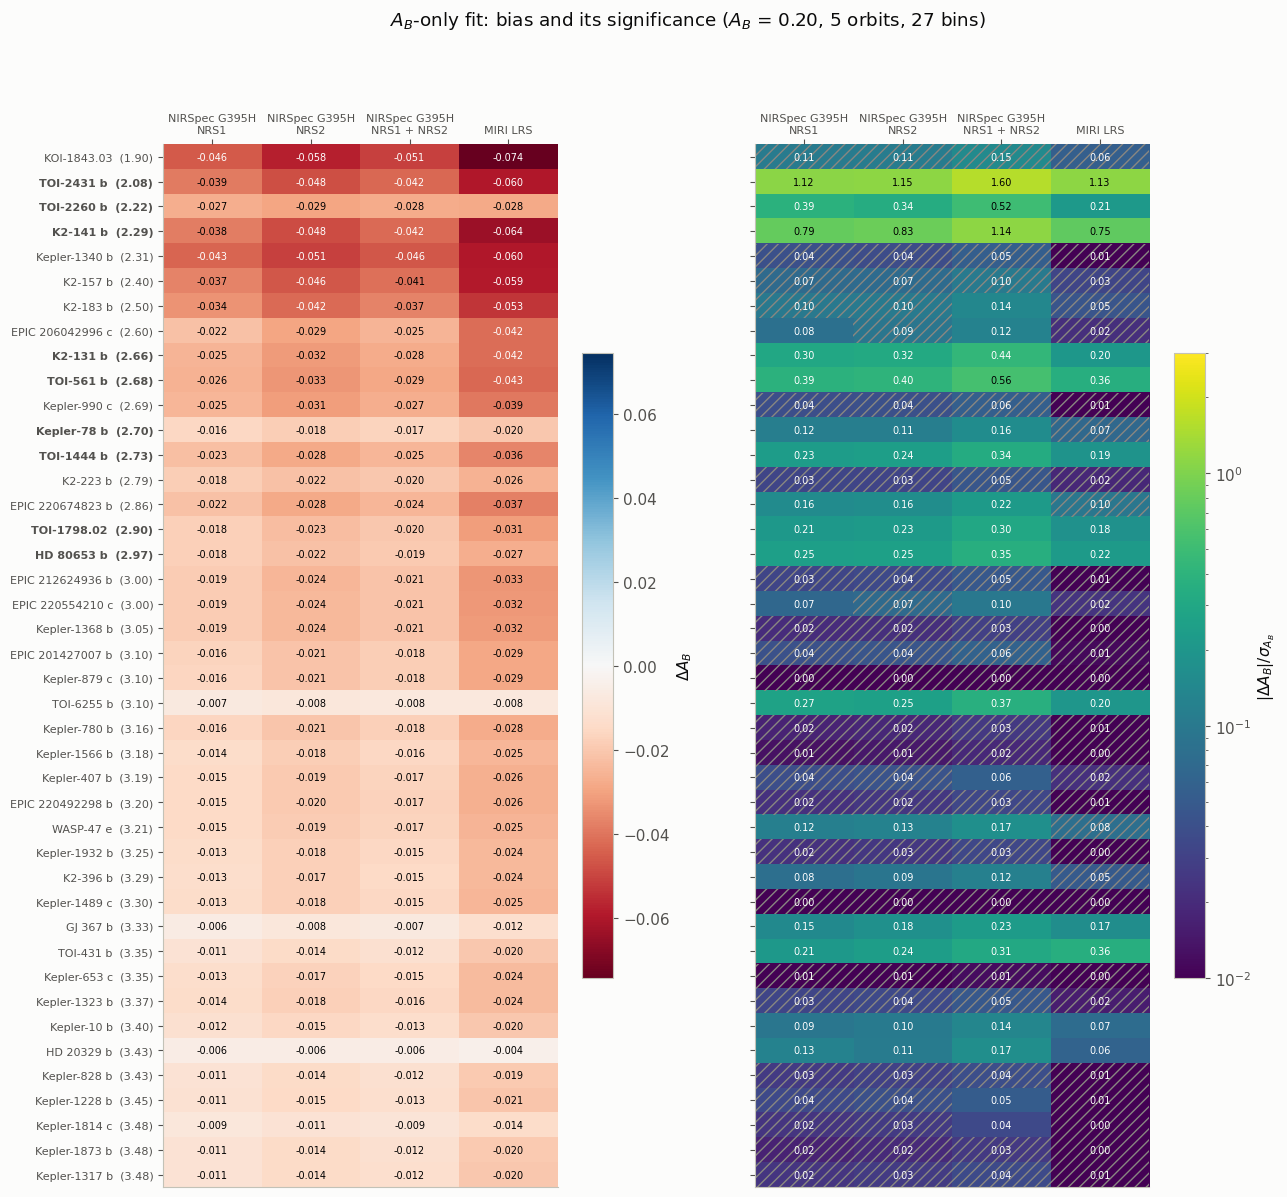

In [8]:
PAPER_MODE = False
fig = heatmap_figure("naive")
paper_figure("planetcomp_heatmap_AB", PAPER_MODE, fig=fig)
plt.show()

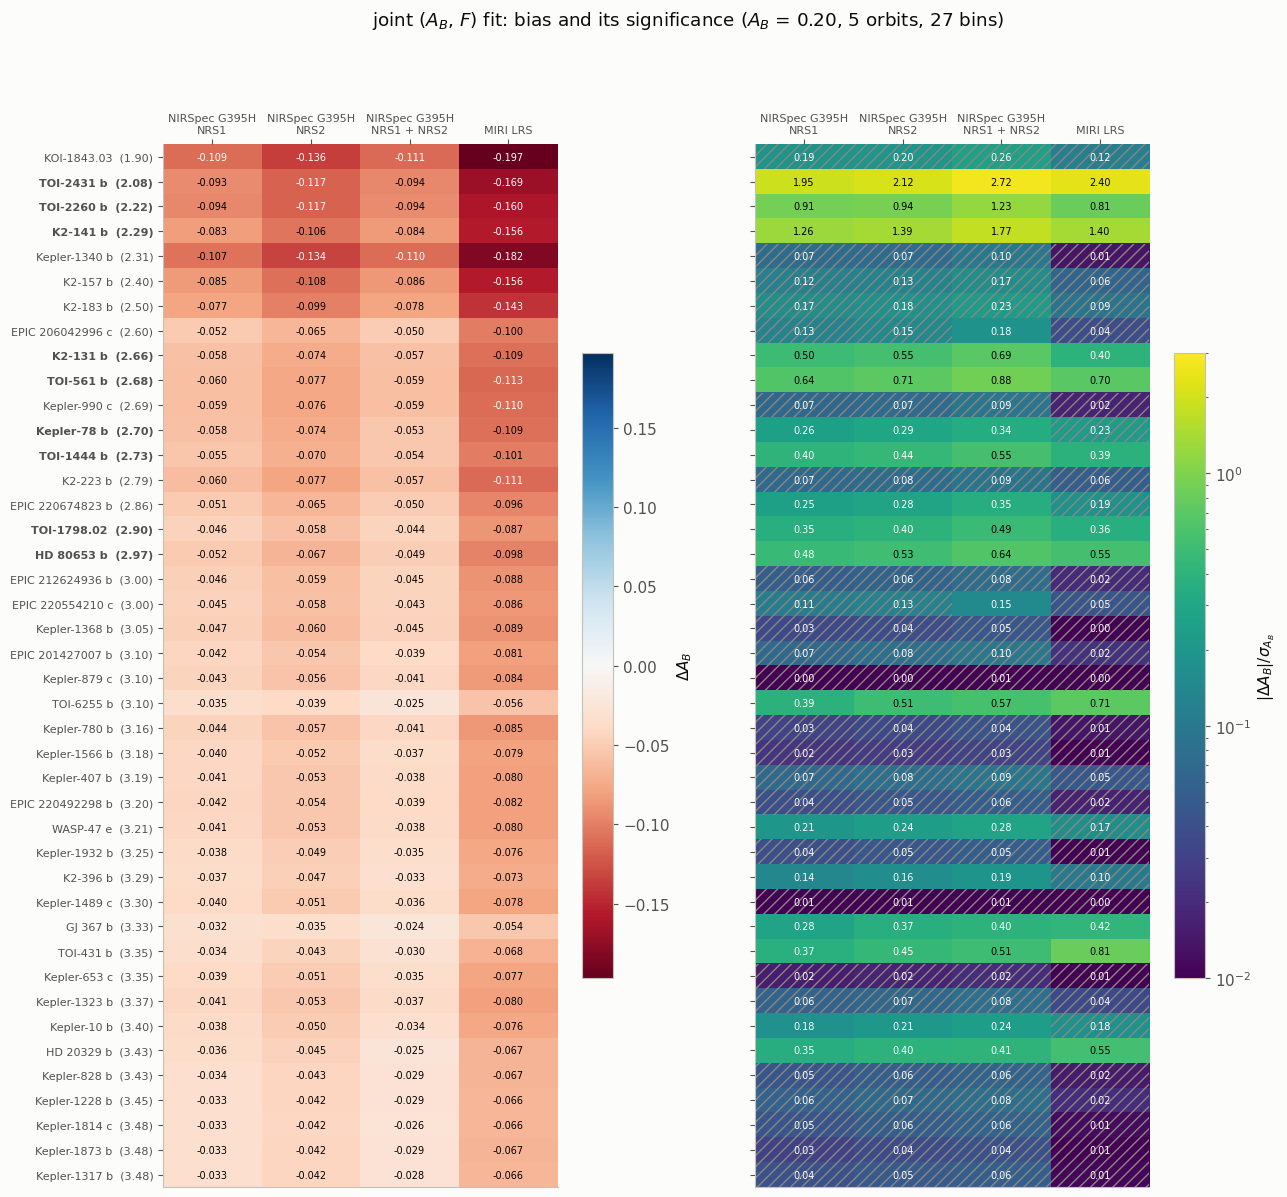

In [9]:
PAPER_MODE = False
fig = heatmap_figure("naive_redist")
paper_figure("planetcomp_heatmap_joint", PAPER_MODE, fig=fig)
plt.show()

## 5. The paper planets in the population
`PAPER_PLANETS` is the paper's sample (confirmed rocky, $a/R_\star < 3$, ESM > 4; see `HItargets_utils.py`). This section places it in the population: each planet's best band and best $|\Delta A_B|/\sigma_{A_B}$ per fit, its rank in the sample by that number and by $a/R_\star$, and one figure of best $|\Delta A_B|/\sigma_{A_B}$ against $a/R_\star$ with the paper planets labelled.

What to look for: whether the paper planets form the upper envelope of the population, which non-members sit among them (and why they are not in the sample: $a/R_\star$, radius, or no curated geometry), and how far the faint majority sits below the dotted line.

In [10]:
best = fits[fits.has_noise].sort_values("bias_sigma", ascending=False).groupby(["name", "fit"], as_index=False).head(1).pivot(index="name", columns="fit", values=["band", "bias_sigma"])
best.columns = [f"{col} ({'AB' if fit == 'naive' else 'joint'})" for col, fit in best.columns]   # flat columns: "band (AB)", "bias_sigma (joint)", ...
summary = sample.set_index("name")[["paper", "a_rs", "rp_rearth", "kmag", "esm"]].join(best).dropna(subset=["bias_sigma (AB)"])
for c in ("band (AB)", "band (joint)"): summary[c] = summary[c].map(lambda b: BAND_LABEL.get(b, b))
summary["rank by bias/sigma (AB)"] = summary["bias_sigma (AB)"].rank(ascending=False).astype(int)
summary["rank by a/R*"] = summary.a_rs.rank().astype(int)
summary = summary.sort_values("bias_sigma (AB)", ascending=False)

print("PAPER_PLANETS in the population (ranks within the fitted sample):")
show(summary[summary.paper].drop(columns="paper"))
above = summary[~summary.paper & (summary["bias_sigma (AB)"] > summary.loc[summary.paper, "bias_sigma (AB)"].min())]
print(f"\n{len(above)} non-members with a best |bias|/sigma (A_B-only) above the weakest paper planet:")
show(above.drop(columns="paper"))

PAPER_PLANETS in the population (ranks within the fitted sample):


,a_rs,rp_rearth,kmag,esm,band (AB),band (joint),bias_sigma (AB),bias_sigma (joint),rank by bias/sigma (AB),rank by a/R*
name,,,,,,,,,,
TOI-2431 b,2.08,1.51,7.55,26,NIRSpec G395H NRS1 + NRS2,NIRSpec G395H NRS1 + NRS2,1.598752,2.724277,1,2
K2-141 b,2.29,1.51,8.4,16.1,NIRSpec G395H NRS1 + NRS2,NIRSpec G395H NRS1 + NRS2,1.138854,1.772528,2,4
TOI-561 b,2.68,1.4,8.39,7.93,NIRSpec G395H NRS1 + NRS2,NIRSpec G395H NRS1 + NRS2,0.555846,0.883940,3,10
TOI-2260 b,2.22,1.62,8.68,8.63,NIRSpec G395H NRS1 + NRS2,NIRSpec G395H NRS1 + NRS2,0.515576,1.226323,4,3
K2-131 b,2.66,1.69,10.1,4.32,NIRSpec G395H NRS1 + NRS2,NIRSpec G395H NRS1 + NRS2,0.440761,0.689918,5,9
HD 80653 b,2.97,1.62,8.02,5.75,NIRSpec G395H NRS1 + NRS2,NIRSpec G395H NRS1 + NRS2,0.354936,0.642677,8,17
TOI-1444 b,2.73,1.4,9.06,5.11,NIRSpec G395H NRS1 + NRS2,NIRSpec G395H NRS1 + NRS2,0.336591,0.554115,9,13
TOI-1798.02,2.9,1.4,9.24,6.26,NIRSpec G395H NRS1 + NRS2,NIRSpec G395H NRS1 + NRS2,0.304677,0.487928,10,16
Kepler-78 b,2.7,1.2,9.59,4.42,NIRSpec G395H NRS1 + NRS2,NIRSpec G395H NRS1 + NRS2,0.161652,0.341076,15,12



6 non-members with a best |bias|/sigma (A_B-only) above the weakest paper planet:


,a_rs,rp_rearth,kmag,esm,band (AB),band (joint),bias_sigma (AB),bias_sigma (joint),rank by bias/sigma (AB),rank by a/R*
name,,,,,,,,,,
TOI-6255 b,3.1,1.08,8.07,21.9,NIRSpec G395H NRS1 + NRS2,MIRI LRS,0.368079,0.705366,6,22
TOI-431 b,3.35,1.28,6.72,15.4,MIRI LRS,MIRI LRS,0.360348,0.807313,7,33
GJ 367 b,3.33,0.699,5.78,18.4,NIRSpec G395H NRS1 + NRS2,MIRI LRS,0.228504,0.423119,11,32
EPIC 220674823 b,2.86,1.6,10.3,2.96,NIRSpec G395H NRS1 + NRS2,NIRSpec G395H NRS1 + NRS2,0.224401,0.349561,12,15
WASP-47 e,3.21,1.81,10.2,2.84,NIRSpec G395H NRS1 + NRS2,NIRSpec G395H NRS1 + NRS2,0.170752,0.279405,13,28
HD 20329 b,3.43,1.72,7.12,10.2,NIRSpec G395H NRS1 + NRS2,MIRI LRS,0.165739,0.545095,14,37


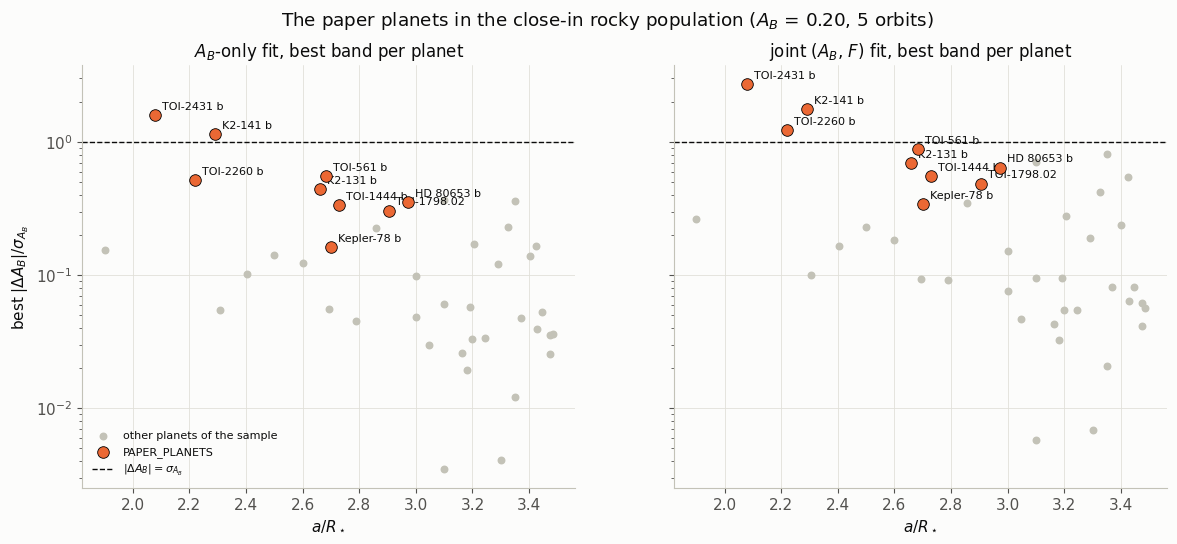

In [11]:
PAPER_MODE = False
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, tag in zip(axs, ("AB", "joint")):
    y = summary[f"bias_sigma ({tag})"].to_numpy(float); ok = np.isfinite(y)
    ax.scatter(summary.a_rs[ok & ~summary.paper], y[ok & ~summary.paper], s=22, color=AXIS, zorder=2, label="other planets of the sample")
    ax.scatter(summary.a_rs[ok & summary.paper], y[ok & summary.paper], s=70, color=C_HI, edgecolor="k", linewidths=.6, zorder=4, label="PAPER_PLANETS")
    for nm in summary.index[ok & summary.paper]: ax.annotate(nm, (summary.a_rs[nm], summary[f"bias_sigma ({tag})"][nm]), xytext=(5, 4), textcoords="offset points", fontsize=8)
    ax.axhline(1., color=INK, ls="--", lw=1, label=r"$|\Delta A_B| = \sigma_{A_B}$")
    ax.set_yscale("log"); ax.set_xlabel(r"$a/R_\star$"); ax.set_title(f"{FITS['naive' if tag == 'AB' else 'naive_redist']}, best band per planet")
axs[0].set_ylabel(r"best $|\Delta A_B| / \sigma_{A_B}$"); axs[0].legend(loc="lower left", fontsize=8)
fig.suptitle(f"The paper planets in the close-in rocky population ($A_B$ = {A_B_true:.2f}, {n_orbits} orbits)")
paper_figure("planetcomp_population", PAPER_MODE, fig=fig)
plt.show()